<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana12/RegresionLinealPesos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
N = 15
x = np.linspace(0, 10, N)
b_real = 2.0
m_real = 1.8

sigma_y = 0.2 + 0.2*x

y_real = b_real + m_real * x
y = y_real + np.random.normal(0, sigma_y, N)

<ErrorbarContainer object of 3 artists>

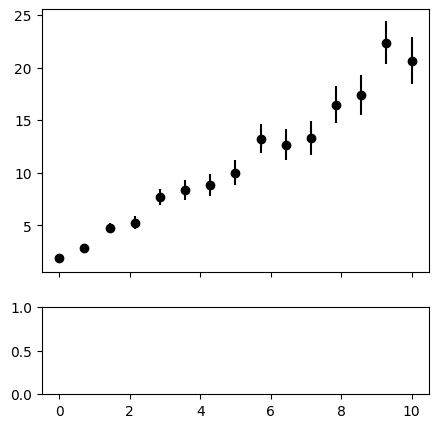

In [8]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')

In [9]:
# Programar minimos cuadrados ponderados
X = np.column_stack((np.ones(N),x))
X

array([[ 1.        ,  0.        ],
       [ 1.        ,  0.71428571],
       [ 1.        ,  1.42857143],
       [ 1.        ,  2.14285714],
       [ 1.        ,  2.85714286],
       [ 1.        ,  3.57142857],
       [ 1.        ,  4.28571429],
       [ 1.        ,  5.        ],
       [ 1.        ,  5.71428571],
       [ 1.        ,  6.42857143],
       [ 1.        ,  7.14285714],
       [ 1.        ,  7.85714286],
       [ 1.        ,  8.57142857],
       [ 1.        ,  9.28571429],
       [ 1.        , 10.        ]])

In [11]:
w = 1/sigma_y**2
w

array([25.        ,  8.50694444,  4.23875433,  2.53099174,  1.68038409,
        1.19628906,  0.89481373,  0.69444444,  0.55454957,  0.45303254,
        0.37703909,  0.31867846,  0.27288928,  0.23630401,  0.20661157])

In [12]:
# Ecuaciones de minimos cuadrados
A = X.T @ (w[:,None]*X)
B = X.T @ (w*y)

In [13]:
A

array([[ 47.16172636,  51.81366603],
       [ 51.81366603, 224.21094158]])

In [14]:
B

array([181.29177552, 504.24042992])

In [15]:
beta_hat = np.linalg.solve(A,B)
beta_hat

array([1.84055001, 1.82361656])

In [17]:
b,m = beta_hat
_x = np.linspace(0,10,100)
_y = b + m*_x

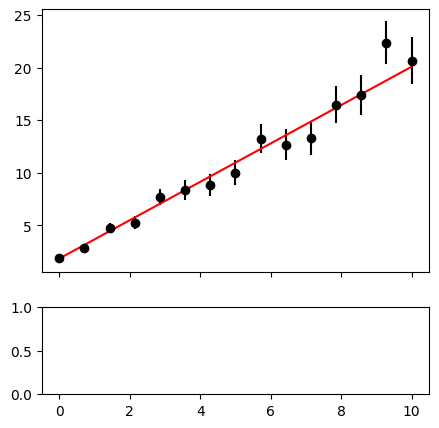

In [18]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')
ax1.plot(_x,_y,color='r')